# Handling geographic coordinates

## Loading the data

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

housing = pd.read_csv("../data/housing.csv")
train_set, test_set = train_test_split(
    housing, test_size=0.2, random_state=42,
    stratify=pd.cut(housing["median_income"], bins=[0., 1.5, 3.0, 4.5, 6., np.inf], labels=[1, 2, 3, 4, 5]))

X_train = train_set.drop("median_house_value", axis=1)  # features
y_train = train_set["median_house_value"].copy()        # target (labels)

## Why coordinates are hard for models

Geographic coordinates present unique challenges for machine learning models:

1. **Non-linear spatial relationships**: Housing prices don't increase or decrease monotonically with latitude or longitude. A district at latitude 37.5° isn't inherently "better" than one at 36.5°—the relationship is highly non-linear and location-dependent.

2. **Interaction effects**: Latitude and longitude only become meaningful *together*. The point (37.7749, -122.4194) is San Francisco, but neither coordinate alone carries that information. Linear models cannot capture this interaction without explicit feature engineering.

3. **Distance matters, not absolute position**: What typically matters is *proximity* to important locations (coast, city centers, employment hubs), not the raw coordinates themselves.

4. **Wrap-around and scale issues**: Longitude wraps at ±180°, and the actual ground distance represented by 1° varies with latitude.

To address these challenges, we can transform coordinates into more useful features:
- **Cluster membership**: Group districts into geographic regions
- **Distance-based features**: Measure proximity to cluster centers or points of interest
- **Similarity scores**: Use kernel functions to capture "nearness" to important locations

## K-means for geographic clustering

K-means is a *clustering* algorithm (unsupervised learning) that we can use to group districts into similar geographic regions. To do this, we'll use the geographic coordinates of the districts and group them into a fixed number of geographic regions.

In [ ]:
from sklearn.cluster import KMeans

# Apply K-means with k=6 (for example, to divide California into 6 regions)
kmeans = KMeans(n_clusters=6, random_state=42)
X_train["region_cluster"] = kmeans.fit_predict(X_train[["latitude", "longitude"]])
X_train[["latitude", "longitude", "region_cluster"]].head()

,latitude,longitude,region_cluster
12655,38.52,-121.46,3
15502,33.09,-117.23,4
2908,35.37,-119.04,5
14053,32.75,-117.13,4
20496,34.28,-118.70,0


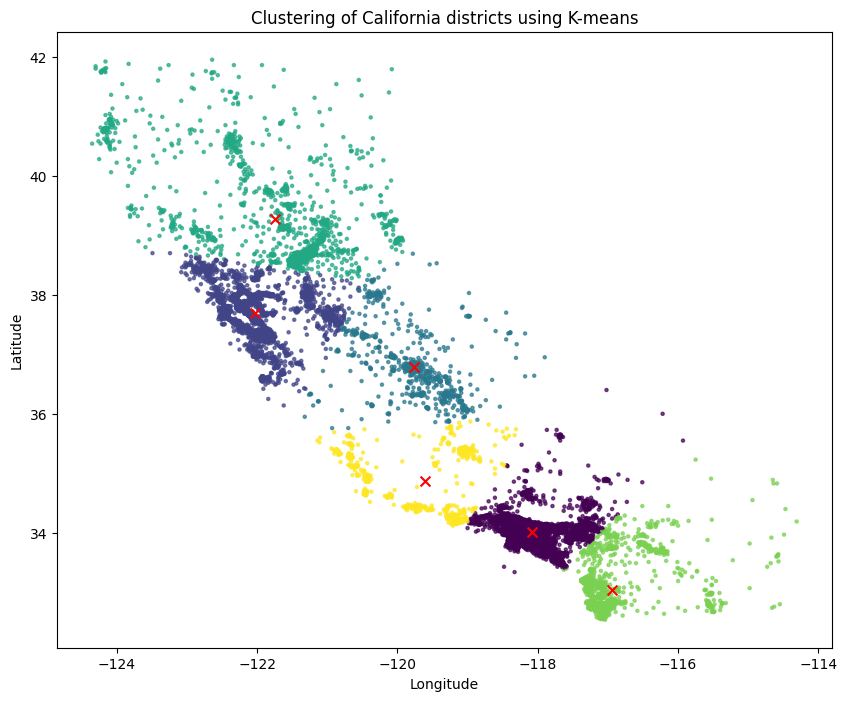

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
plt.scatter(X_train["longitude"], X_train["latitude"],
            c=X_train["region_cluster"], cmap="viridis",
            s=5, alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 1], kmeans.cluster_centers_[:, 0],
            c="red", s=50, marker="x")
plt.title("Clustering of California districts using K-means")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

We could create a [custom transformer](custom_transformers.ipynb) for this process:

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin

class RegionClusterTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=6, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y=None):
        """Fits the KMeans model using the 'latitude' and 'longitude' columns of the DataFrame X."""
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(X[["latitude", "longitude"]])
        return self

    def transform(self, X):
        """Returns a copy of X with a 'region_cluster' column containing the cluster of each record."""
        X_transformed = X.copy()
        X_transformed["region_cluster"] = self.kmeans_.predict(X_transformed[["latitude", "longitude"]])
        return X_transformed

In [ ]:
transformer = RegionClusterTransformer(n_clusters=6, random_state=42)
transformer.fit(X_train)
housing_transformed = transformer.transform(X_train)
housing_transformed[["latitude", "longitude", "region_cluster"]].head()

,latitude,longitude,region_cluster
12655,38.52,-121.46,3
15502,33.09,-117.23,4
2908,35.37,-119.04,5
14053,32.75,-117.13,4
20496,34.28,-118.70,0


## Distance to the centroid as a feature

However, housing prices are not only related by the cluster of districts they belong to, but districts closer to the cluster center are likely to have higher prices. Therefore, it would be useful to create a feature that captures the "proximity" to the cluster centers.

In [ ]:
class DistanceClusterTransformer(BaseEstimator, TransformerMixin):
    """
    Custom transformer for grouping geographic locations using K-means.
    Expects a DataFrame with at least two columns: 'latitude' and 'longitude'.
    """
    def __init__(self, n_clusters=8, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y=None):
        coords = X[["latitude", "longitude"]].values
        self.kmeans_ = KMeans(n_clusters=self.n_clusters, random_state=self.random_state)
        self.kmeans_.fit(coords)
        return self

    def transform(self, X):
        X_trans = X.copy()
        coords = X_trans[["latitude", "longitude"]].values

        cluster_labels = self.kmeans_.predict(coords)
        X_trans["geo_cluster"] = cluster_labels

        # Euclidean distance from each point to the centroid of its own cluster
        assigned_centroids = self.kmeans_.cluster_centers_[cluster_labels]
        X_trans["distance_to_centroid"] = np.linalg.norm(coords - assigned_centroids, axis=1)
        return X_trans

In [ ]:
geo_cluster_transformer = DistanceClusterTransformer(n_clusters=5)
geo_cluster_transformer.fit(X_train[["longitude", "latitude"]])
housing_geo_clusters = geo_cluster_transformer.transform(X_train[["longitude", "latitude"]])
housing_geo_clusters.head()

,longitude,latitude,geo_cluster,distance_to_centroid
12655,-121.46,38.52,3,0.810514
15502,-117.23,33.09,4,0.287789
2908,-119.04,35.37,2,0.995066
14053,-117.13,32.75,4,0.361414
20496,-118.70,34.28,0,0.614293


## Similarity with `rbf_kernel`

The `rbf_kernel` function calculates the similarity between two datasets through the *radial basis function* (RBF), returning a value between 0 and 1.
For example, if we assumed that properties around 35 years old increase in value due to some particularity, we could measure the distance of each one to those that are 35 years old and assign a similarity value.

In [ ]:
from sklearn.metrics.pairwise import rbf_kernel

age_simil_35 = rbf_kernel(X_train[["housing_median_age"]], [[35]], gamma=0.1)
age_simil_35[:5]

array([[2.73237224e-02],
       [8.93948745e-35],
       [3.03539138e-04],
       [5.55951324e-06],
       [1.66155727e-03]])

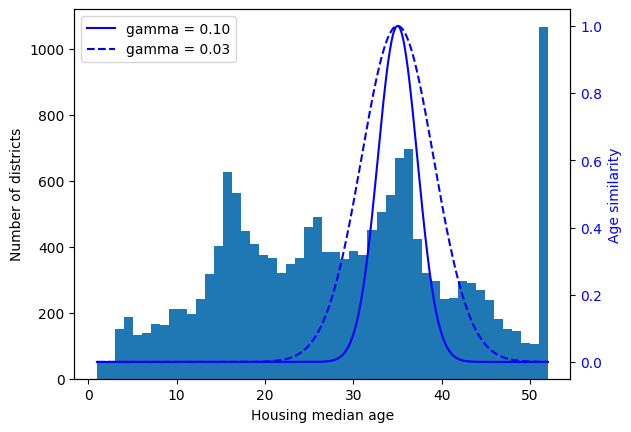

In [ ]:
ages = np.linspace(X_train["housing_median_age"].min(),
                   X_train["housing_median_age"].max(),
                   500).reshape(-1, 1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages, [[35]], gamma=gamma1)
rbf2 = rbf_kernel(ages, [[35]], gamma=gamma2)

fig, ax1 = plt.subplots()

ax1.set_xlabel("Housing median age")
ax1.set_ylabel("Number of districts")
ax1.hist(X_train["housing_median_age"], bins=50)

ax2 = ax1.twinx()  # twin axis sharing the same x-axis
color = "blue"
ax2.plot(ages, rbf1, color=color, label="gamma = 0.10")
ax2.plot(ages, rbf2, color=color, label="gamma = 0.03", linestyle="--")
ax2.tick_params(axis="y", labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)

plt.legend(loc="upper left")
plt.show()

We can see how the `gamma` value allows adjusting the similarity between the data, widening or narrowing the RBF function, which is a normal (Gaussian) distribution centered on the reference value. On the right, we can see the scale from 0 to 1 of similarity that records close to the reference value will return.

### Similarity to the centroids

Instead of the distance, we can use `rbf_kernel` to measure the proximity of each district to *every* cluster center, obtaining one similarity feature per cluster. The `sample_weight` parameter lets K-means give more weight to the expensive districts when placing the centers.

In [ ]:
class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=10, gamma=1.0, random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state

    def fit(self, X, y=None, sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters, n_init=10,
                              random_state=self.random_state)
        self.kmeans_.fit(X, sample_weight=sample_weight)
        return self  # always return self!

    def transform(self, X):
        return rbf_kernel(X, self.kmeans_.cluster_centers_, gamma=self.gamma)

    def get_feature_names_out(self, names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

In [ ]:
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
similarities = cluster_simil.fit_transform(X_train[["latitude", "longitude"]],
                                           sample_weight=y_train)
similarities[:3].round(2)

array([[0.  , 0.31, 0.  , 0.85, 0.  , 0.  , 0.  , 0.  , 0.16, 0.49],
       [0.11, 0.  , 0.  , 0.  , 0.94, 0.  , 0.  , 0.41, 0.  , 0.  ],
       [0.11, 0.  , 0.15, 0.  , 0.  , 0.37, 0.  , 0.02, 0.  , 0.  ]])

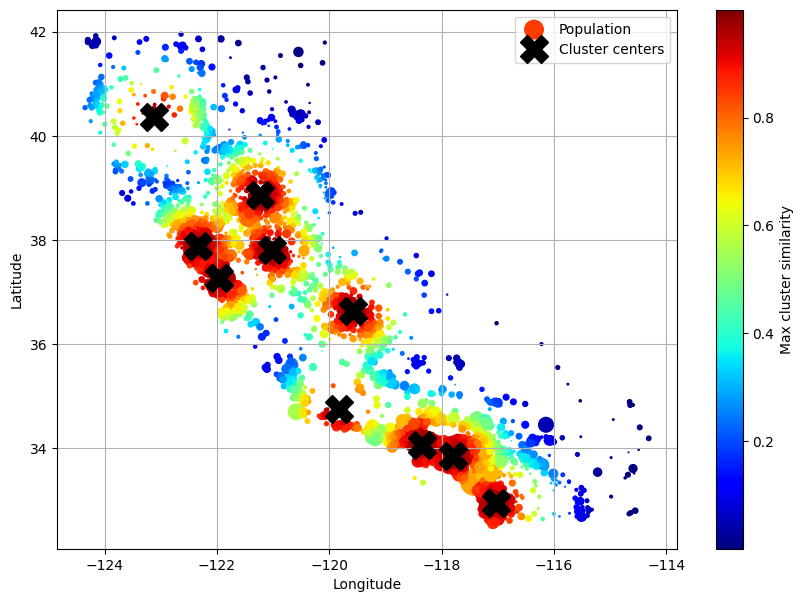

In [ ]:
housing_renamed = X_train.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)

housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["Population"] / 100, label="Population",
                     c="Max cluster similarity",
                     cmap="jet", colorbar=True,
                     legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1],
         cluster_simil.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=20,
         label="Cluster centers")
plt.legend(loc="upper right")
plt.show()

`ClusterSimilarity` is the transformer the California pipeline uses for `latitude` and `longitude` ([`../workflow/05_preprocessing_pipeline.ipynb`](../workflow/05_preprocessing_pipeline.ipynb)); its `n_clusters` and `gamma` are hyperparameters that can be tuned together with the model's ([`../workflow/07_hyperparameter_tuning.ipynb`](../workflow/07_hyperparameter_tuning.ipynb)).